In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from sklearn.utils import class_weight 
import numpy as np

# 전처리된 데이터가 있는 경로
BASE_DIR = "data/processed"
TRAIN_PATH = os.path.join(BASE_DIR, "train.npz")
VAL_PATH = os.path.join(BASE_DIR, "val.npz")
TEST_PATH = os.path.join(BASE_DIR, "test.npz")
OUT_DIR = "data/processed"
MODEL_DIR = "model_output"
MODEL_PATH = os.path.join(MODEL_DIR, "best_audio_model.h5")

# 모델과 그래프를 저장할 폴더 생성
OUTPUT_DIR = "model_output"
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)

# 하이퍼파라미터
NUM_CLASSES = 4       # 클래스 개수 (Chatting, Game, web_surfing, Writing)
BATCH_SIZE = 32       # 한 번에 학습할 데이터 양
EPOCHS = 50           # 최대 학습 횟수
LEARNING_RATE = 0.001 # 학습 속도

print(f"설정 완료. 데이터 경로: {BASE_DIR}")
print(f"결과 저장 경로: {OUTPUT_DIR}")

설정 완료. 데이터 경로: data/processed
결과 저장 경로: model_output


In [2]:
def load_data():
    if not os.path.exists(TRAIN_PATH):
        raise FileNotFoundError(f"파일을 찾을 수 없습니다")

    # 1. Train 데이터 로드
    data_tr = np.load(TRAIN_PATH)
    X_train, y_train = data_tr['X'], data_tr['y']
    # CNN 입력을 위해 채널 차원 추가: (N, 64, T) -> (N, 64, T, 1)
    X_train = np.expand_dims(X_train, axis=-1) 
    y_train = to_categorical(y_train, NUM_CLASSES)

    # 2. Validation 데이터 로드
    data_val = np.load(VAL_PATH)
    X_val, y_val = data_val['X'], data_val['y']
    X_val = np.expand_dims(X_val, axis=-1)
    y_val = to_categorical(y_val, NUM_CLASSES)

    # 3. Test 데이터 로드
    data_te = np.load(TEST_PATH)
    X_test, y_test = data_te['X'], data_te['y']
    X_test = np.expand_dims(X_test, axis=-1)
    y_test = to_categorical(y_test, NUM_CLASSES)

    return (X_train, y_train), (X_val, y_val), (X_test, y_test)

# 실행 및 확인
(X_train, y_train), (X_val, y_val), (X_test, y_test) = load_data()
input_shape = X_train.shape[1:]

print(f"훈련 데이터 형태: {X_train.shape}")
print(f"검증 데이터 형태: {X_val.shape}")
print(f"테스트 데이터 형태: {X_test.shape}")
print(f"입력 모양: {input_shape}")

훈련 데이터 형태: (20902, 64, 1001, 1)
검증 데이터 형태: (4449, 64, 1001, 1)
테스트 데이터 형태: (2197, 64, 1001, 1)
입력 모양: (64, 1001, 1)


In [3]:
def build_model(input_shape):
    model = Sequential([
        Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=input_shape),
        MaxPooling2D((2, 4)), # 시간축 정보를 더 많이 압축
        Dropout(0.25),

        Conv2D(64, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 4)),
        Dropout(0.25),

        Conv2D(128, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 4)),
        Dropout(0.25),

        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(NUM_CLASSES, activation='softmax')
    ])
    
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model = build_model(input_shape)
model.summary()

Instructions for updating:
If using Keras pass *_constraint arguments to layers.
Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d (Conv2D)              (None, 64, 1001, 32)      320       
_________________________________________________________________
max_pooling2d (MaxPooling2D) (None, 32, 250, 32)       0         
_________________________________________________________________
dropout (Dropout)            (None, 32, 250, 32)       0         
_________________________________________________________________
conv2d_1 (Conv2D)            (None, 32, 250, 64)       18496     
_________________________________________________________________
max_pooling2d_1 (MaxPooling2 (None, 16, 62, 64)        0         
_________________________________________________________________
dropout_1 (Dropout)          (None, 16, 62, 64)        0         
_________________________________________

In [4]:
model_path = os.path.join(OUTPUT_DIR, "best_audio_model.h5")
checkpoint = ModelCheckpoint(
    MODEL_PATH, 
    monitor='val_acc',      # <--- [변경] 손실(loss) 대신 정확도(accuracy)를 모니터링
    save_best_only=True, 
    mode='max',                  # <--- [추가] 정확도는 높을수록 좋으므로 mode='max'로 설정
    verbose=1
)

# 7번 동안 성능 향상이 없으면 학습 중단
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

# 학습률 조정: 성능이 정체되면 학습률을 낮춤 (더 세밀하게 학습)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)

print("모델 학습을 시작합니다.")

# --- 1. [핵심] 클래스 가중치 계산 시작 ---
# model.fit에 넣기 위해 y_train (원-핫 인코딩 형태)을 정수 레이블로 다시 변환합니다.
y_integers = np.argmax(y_train, axis=1) 

# sklearn을 사용하여 클래스별 빈도에 반비례하는 '균형 가중치'를 계산합니다.
weights = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(y_integers),
    y=y_integers
)

# Keras fit 함수에 필요한 딕셔너리 형태로 변환합니다.
# (예: {0: 1.5, 1: 0.3, 2: 2.0, 3: 1.0})
class_weights = dict(enumerate(weights))

print(f"계산된 클래스 가중치: {class_weights}")
# --- 클래스 가중치 계산 종료 ---


history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    callbacks=[checkpoint, early_stop, reduce_lr],
    class_weight=class_weights,  # <--- [수정됨] 이 인자를 추가합니다.
    verbose=1
)
print("가중치 적용 후 학습이 완료되었습니다.")

모델 학습을 시작합니다.
계산된 클래스 가중치: {0: 1.5292654375182908, 1: 0.8347444089456869, 2: 1.3736855941114616, 3: 0.704150384045277}
Train on 20902 samples, validate on 4449 samples
Epoch 1/50
20896/20902 [============================>.] - ETA: 0s - loss: 0.4410 - acc: 0.8524
Epoch 00001: val_acc improved from -inf to 0.99798, saving model to model_output\best_audio_model.h5
20902/20902 [==============================] - 224s 11ms/sample - loss: 0.4409 - acc: 0.8525 - val_loss: 0.0649 - val_acc: 0.9980
Epoch 2/50
20896/20902 [============================>.] - ETA: 0s - loss: 0.1532 - acc: 0.9542
Epoch 00002: val_acc did not improve from 0.99798
20902/20902 [==============================] - 219s 10ms/sample - loss: 0.1532 - acc: 0.9543 - val_loss: 0.0335 - val_acc: 0.9955
Epoch 3/50
20896/20902 [============================>.] - ETA: 0s - loss: 0.0970 - acc: 0.9722
Epoch 00003: val_acc improved from 0.99798 to 0.99888, saving model to model_output\best_audio_model.h5
20902/20902 [===================

감지된 정확도 키: acc, val_acc


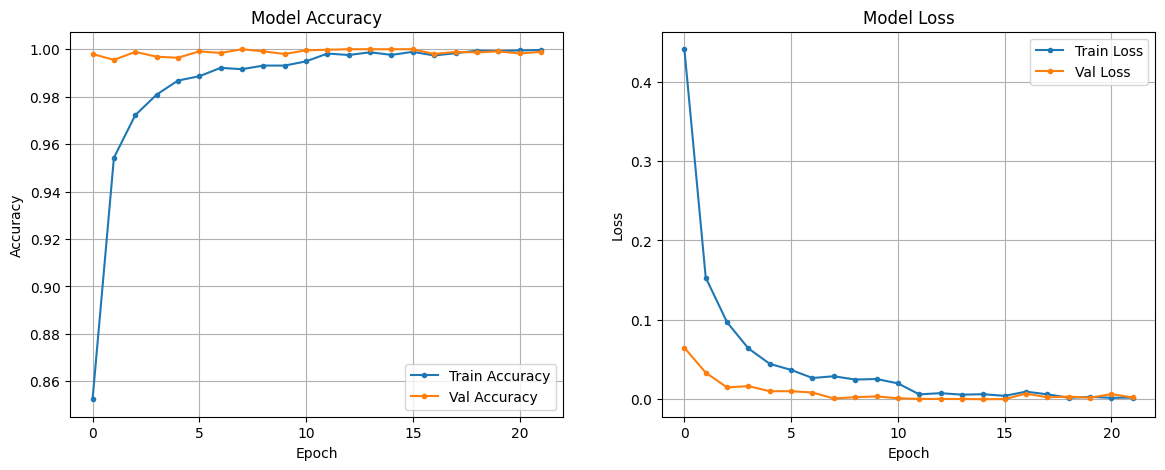

그래프가 'model_output' 폴더에 저장되었습니다.


In [5]:
# history에서 정확도 키가 'accuracy'인지 'acc'인지 자동으로 찾음
acc_key = 'accuracy' if 'accuracy' in history.history else 'acc'
val_acc_key = 'val_accuracy' if 'val_accuracy' in history.history else 'val_acc'

print(f"감지된 정확도 키: {acc_key}, {val_acc_key}")

plt.figure(figsize=(14, 5))

# 1. 정확도 그래프
plt.subplot(1, 2, 1)
plt.plot(history.history[acc_key], label='Train Accuracy', marker='.')
plt.plot(history.history[val_acc_key], label='Val Accuracy', marker='.')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# 2. 손실 그래프
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='.')
plt.plot(history.history['val_loss'], label='Val Loss', marker='.')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# 그래프 저장 및 출력
plt.savefig(os.path.join(OUTPUT_DIR, "training_history.png"))
plt.show()
print(f"그래프가 '{OUTPUT_DIR}' 폴더에 저장되었습니다.")

In [6]:
# [Cell 6]
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\n[최종 테스트 결과]")
print(f"Loss: {loss:.4f}")
print(f"Accuracy: {accuracy:.4f}")


[최종 테스트 결과]
Loss: 1.2249
Accuracy: 0.9449
